In [1]:
import sys
import os
import shutil
import pandas as pd
import tensorflow as tf
import numpy as np
import csv
import sqlite3
from osgeo import gdal
from utils.ACC_train_bestVoter_ensemble import get_sub_bands
import matplotlib.pyplot as plt
local_lib_path = os.path.abspath('./local_libs')
if local_lib_path not in sys.path:
    sys.path.insert(0, local_lib_path)
import umap
import random
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import normalize
import joblib

In [2]:
# ============================================================================
# Load All Models (Scalers, PCAs, and Isolation Forests)
# ============================================================================
 
print("Loading models...")
 
model_dir = '/home/jovyan/private/where_transfer/models'
source_city = "ACC"
voter = "communities"
PRIMARY_PAIR_METHOD = 'diff'
 
# Load Single-Image Pipeline
scaler_single = joblib.load(f'{model_dir}/{source_city}_{voter}_single_scaler.joblib')
pca_single = joblib.load(f'{model_dir}/{source_city}_{voter}_single_pca.joblib')
iso_single = joblib.load(f'{model_dir}/{source_city}_{voter}_single_iso_pca.joblib')
 
# Load Concatenated-Pair Pipeline
scaler_concat = joblib.load(f'{model_dir}/{source_city}_{voter}_pair_concat_scaler.joblib')
pca_concat = joblib.load(f'{model_dir}/{source_city}_{voter}_pair_concat_pca.joblib')
iso_pair_concat = joblib.load(f'{model_dir}/{source_city}_{voter}_pair_concat_iso_pca.joblib')
 
# Load Difference Pipeline
scaler_diff = joblib.load(f'{model_dir}/{source_city}_{voter}_pair_diff_scaler.joblib')
pca_diff = joblib.load(f'{model_dir}/{source_city}_{voter}_pair_diff_pca.joblib')
iso_pair_diff = joblib.load(f'{model_dir}/{source_city}_{voter}_pair_diff_iso_pca.joblib')
 
print("✓ Loaded all models (scalers, PCAs, and Isolation Forests)")

Loading models...
✓ Loaded all models (scalers, PCAs, and Isolation Forests)


In [3]:
root_path = '/home/jovyan/private/slums/data/PARTIMAP'
# Load image function (identical to your training notebook)
def load_and_preprocess_image(fp, sub_bands, norm_data=False):
    img_dataset = gdal.Open(fp)
    img_array = img_dataset.ReadAsArray()
    if norm_data:
        img_array = (img_array - np.min(img_array)) / (np.max(img_array) - np.min(img_array))
    if sub_bands is not None:
        img_array = img_array[sub_bands,:,:]
    return np.transpose(img_array[:, :20, :20], (1, 2, 0))
def retrieve_db(db_path, sql):
    con = sqlite3.connect(db_path)
    return con, pd.read_sql(sql, con = con)
def process_batch_complete(img_l_list, img_r_list):
    """
    Process batch and return BOTH raw and PCA-transformed embeddings.
    """
    
    np_batch_l = np.array(img_l_list)
    np_batch_r = np.array(img_r_list)
    
    # --- BT Prediction ---
    predictions = full_model([np_batch_l, np_batch_r]).numpy()
    
    if predictions.shape[1] == 1:
        batch_probs = predictions.flatten()
        batch_preds = (batch_probs > 0.5).astype(int)
    else:
        batch_preds = np.argmax(predictions, axis=1)
        batch_probs = predictions[:, 1]
    
    # --- Extract RAW Features (256D) ---
    features_l = single_encoder(np_batch_l).numpy()
    features_r = single_encoder(np_batch_r).numpy()
    
    features_l_flat = features_l.reshape(features_l.shape[0], -1)  # (batch, 256)
    features_r_flat = features_r.reshape(features_r.shape[0], -1)  # (batch, 256)
    
    # --- Apply PCA Transformations ---
    
    # Single images: 256D → Scale → PCA → 64D
    features_l_scaled = scaler_single.transform(features_l_flat)
    features_l_pca = pca_single.transform(features_l_scaled)
    
    features_r_scaled = scaler_single.transform(features_r_flat)
    features_r_pca = pca_single.transform(features_r_scaled)
    
    # Pairwise concat: [L,R] → 512D → Scale → PCA → 128D
    pair_concat_raw = np.concatenate([features_l_flat, features_r_flat], axis=1)
    pair_concat_scaled = scaler_concat.transform(pair_concat_raw)
    pair_concat_pca = pca_concat.transform(pair_concat_scaled)
    
    # Pairwise diff: L-R → 256D → Scale → PCA → 64D
    pair_diff_raw = features_l_flat - features_r_flat
    pair_diff_scaled = scaler_diff.transform(pair_diff_raw)
    pair_diff_pca = pca_diff.transform(pair_diff_scaled)
    
    # --- Isolation Forest Predictions ---
    batch_iso_l_class = iso_single.predict(features_l_pca)
    batch_iso_l_score = iso_single.decision_function(features_l_pca)
    
    batch_iso_r_class = iso_single.predict(features_r_pca)
    batch_iso_r_score = iso_single.decision_function(features_r_pca)
    
    batch_iso_concat_class = iso_pair_concat.predict(pair_concat_pca)
    batch_iso_concat_score = iso_pair_concat.decision_function(pair_concat_pca)
    
    batch_iso_diff_class = iso_pair_diff.predict(pair_diff_pca)
    batch_iso_diff_score = iso_pair_diff.decision_function(pair_diff_pca)
    
    # --- Delta Vectors (winner - loser) ---
    # Raw version (256D) - backward compatible
    delta_raw = np.where(
        batch_preds[:, None] == 1,
        features_l_flat - features_r_flat,
        features_r_flat - features_l_flat
    )
    
    # PCA version (64D) - for faster visualization
    delta_pca = np.where(
        batch_preds[:, None] == 1,
        features_l_pca - features_r_pca,
        features_r_pca - features_l_pca
    )
    
    return {
        # Predictions
        'preds': batch_preds,
        'probs': batch_probs,
        
        # Isolation Forest results
        'iso_l_class': batch_iso_l_class,
        'iso_l_score': batch_iso_l_score,
        'iso_r_class': batch_iso_r_class,
        'iso_r_score': batch_iso_r_score,
        'iso_concat_class': batch_iso_concat_class,
        'iso_concat_score': batch_iso_concat_score,
        'iso_diff_class': batch_iso_diff_class,
        'iso_diff_score': batch_iso_diff_score,
        
        # RAW embeddings (256D/512D)
        'features_l_raw': features_l_flat,
        'features_r_raw': features_r_flat,
        'pair_concat_raw': pair_concat_raw,
        'pair_diff_raw': pair_diff_raw,
        'delta_raw': delta_raw,
        
        # PCA embeddings (64D/128D)
        'features_l_pca': features_l_pca,
        'features_r_pca': features_r_pca,
        'pair_concat_pca': pair_concat_pca,
        'pair_diff_pca': pair_diff_pca,
        'delta_pca': delta_pca
    }

def load_pairs(city, voter, root_path = '/home/jovyan/private/slums/data/PARTIMAP'):
    db_path = f'{root_path}/votes/db/{city}/{city}_voterAI.db'
    tbl_name = f'{city}_{voter}_votes'
    sql = f"select * from " + tbl_name
    con, city_data = retrieve_db(db_path, sql)
    
    return con, city_data

In [4]:
source_city = "ACC"
target_city = "NBO"
voter = "communities"
d_src = "S1_200m"

out_result = f"{source_city}_on_{target_city}"
out_folder = f"results_BT/{out_result}"
if os.path.exists(out_folder):
    shutil.rmtree(out_folder)
os.mkdir(out_folder)

con, target_city_data = load_pairs(target_city, voter)

base_model = f"{source_city}_voter_{voter}"
model_name = f"{base_model}_ensembleVoter"

sub_bands, n_width, n_height, n_channels = get_sub_bands(d_src)

model_dir = f'{root_path}/trained_models/voter/{model_name}_{d_src}_1_bradley_terry.ckpt'

In [5]:
full_model = tf.keras.models.load_model(model_dir)
# nested_model = full_model.get_layer('model_1_1_1_1_2_1_3_1_4_1_5')
nested_model = full_model.layers[2]
single_encoder = nested_model.get_layer('feature_extractor')

2026-05-23 01:06:40.473705: W tensorflow/core/common_runtime/gpu/gpu_bfc_allocator.cc:42] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was 0.


In [6]:
# ============================================================================
# Batch Processing
# ============================================================================
 
print("\nProcessing batches...")
 
# For CSV
all_preds = []
all_probs = []
all_iso_l_class, all_iso_l_score = [], []
all_iso_r_class, all_iso_r_score = [], []
all_iso_concat_class, all_iso_concat_score = [], []
all_iso_diff_class, all_iso_diff_score = [], []
 
# For numpy arrays - RAW
all_features_l_raw = []
all_features_r_raw = []
all_pair_concat_raw = []
all_pair_diff_raw = []
all_delta_raw = []
 
# For numpy arrays - PCA
all_features_l_pca = []
all_features_r_pca = []
all_pair_concat_pca = []
all_pair_diff_pca = []
all_delta_pca = []
 
BATCH_SIZE = 64
total_pairs = len(target_city_data)
 
for i in range(0, total_pairs, BATCH_SIZE):
    if i % (BATCH_SIZE * 10) == 0:
        print(f"  {i}/{total_pairs} ({i/total_pairs*100:.1f}%)", end='\r')
    
    batch_df = target_city_data.iloc[i: i + BATCH_SIZE]
    
    batch_l = [load_and_preprocess_image(f"{root_path}/{row.left}", sub_bands) 
               for row in batch_df.itertuples()]
    batch_r = [load_and_preprocess_image(f"{root_path}/{row.right}", sub_bands) 
               for row in batch_df.itertuples()]
    
    results = process_batch_complete(batch_l, batch_r)
    
    # CSV data
    all_preds.extend(results['preds'])
    all_probs.extend(results['probs'])
    all_iso_l_class.extend(results['iso_l_class'])
    all_iso_l_score.extend(results['iso_l_score'])
    all_iso_r_class.extend(results['iso_r_class'])
    all_iso_r_score.extend(results['iso_r_score'])
    all_iso_concat_class.extend(results['iso_concat_class'])
    all_iso_concat_score.extend(results['iso_concat_score'])
    all_iso_diff_class.extend(results['iso_diff_class'])
    all_iso_diff_score.extend(results['iso_diff_score'])
    
    # RAW embeddings
    all_features_l_raw.extend(results['features_l_raw'])
    all_features_r_raw.extend(results['features_r_raw'])
    all_pair_concat_raw.extend(results['pair_concat_raw'])
    all_pair_diff_raw.extend(results['pair_diff_raw'])
    all_delta_raw.extend(results['delta_raw'])
    
    # PCA embeddings
    all_features_l_pca.extend(results['features_l_pca'])
    all_features_r_pca.extend(results['features_r_pca'])
    all_pair_concat_pca.extend(results['pair_concat_pca'])
    all_pair_diff_pca.extend(results['pair_diff_pca'])
    all_delta_pca.extend(results['delta_pca'])
 
print(f"\n✓ Processed {total_pairs} pairs")


Processing batches...


2026-05-23 01:06:45.358322: W tensorflow/stream_executor/gpu/asm_compiler.cc:230] Falling back to the CUDA driver for PTX compilation; ptxas does not support CC 8.9
2026-05-23 01:06:45.358339: W tensorflow/stream_executor/gpu/asm_compiler.cc:233] Used ptxas at ptxas
2026-05-23 01:06:45.358522: W tensorflow/stream_executor/gpu/redzone_allocator.cc:314] UNIMPLEMENTED: ptxas ptxas too old. Falling back to the driver to compile.
Relying on driver to perform ptx compilation. 
Modify $PATH to customize ptxas location.
This message will be only logged once.


  56320/56590 (99.5%)
✓ Processed 56590 pairs


In [7]:
# ============================================================================
# Save CSV (Same as before)
# ============================================================================
 
print("\nSaving CSV...")
 
target_city_data['model_prediction'] = all_preds
target_city_data['bt_probability'] = all_probs
 
target_city_data['iso_left_class'] = all_iso_l_class
target_city_data['iso_left_score'] = all_iso_l_score
target_city_data['iso_right_class'] = all_iso_r_class
target_city_data['iso_right_score'] = all_iso_r_score
 
target_city_data['iso_pair_concat_class'] = all_iso_concat_class
target_city_data['iso_pair_concat_score'] = all_iso_concat_score
target_city_data['iso_pair_diff_class'] = all_iso_diff_class
target_city_data['iso_pair_diff_score'] = all_iso_diff_score
 
# # Primary method for viz compatibility
# if PRIMARY_PAIR_METHOD == 'diff':
#     target_city_data['iso_pair_class'] = all_iso_diff_class
#     target_city_data['iso_pair_score'] = all_iso_diff_score
# else:
#     target_city_data['iso_pair_class'] = all_iso_concat_class
#     target_city_data['iso_pair_score'] = all_iso_concat_score
 
csv_path = f"{out_folder}/{out_result}_inference.csv"
target_city_data.to_csv(csv_path, index=False)
print(f"✓ Saved CSV: {csv_path}")
 
# ============================================================================
# Save NumPy Arrays - RAW Embeddings
# ============================================================================
 
print("\nSaving RAW embeddings (256D/512D)...")
 
# Convert to numpy arrays
features_l_raw = np.array(all_features_l_raw)
features_r_raw = np.array(all_features_r_raw)
pair_concat_raw = np.array(all_pair_concat_raw)
pair_diff_raw = np.array(all_pair_diff_raw)
delta_raw = np.array(all_delta_raw)
 
# Save RAW
np.save(f"{out_folder}/{out_result}_features_left_raw.npy", features_l_raw)
np.save(f"{out_folder}/{out_result}_features_right_raw.npy", features_r_raw)
np.save(f"{out_folder}/{out_result}_pair_concat_raw.npy", pair_concat_raw)
np.save(f"{out_folder}/{out_result}_pair_diff_raw.npy", pair_diff_raw)
np.save(f"{out_folder}/{out_result}_delta_vectors.npy", delta_raw)  # Backward compatible name
 
print(f"✓ Saved RAW embeddings:")
print(f"  - features_left_raw:  {features_l_raw.shape}")
print(f"  - features_right_raw: {features_r_raw.shape}")
print(f"  - pair_concat_raw:    {pair_concat_raw.shape}")
print(f"  - pair_diff_raw:      {pair_diff_raw.shape}")
print(f"  - delta_vectors:      {delta_raw.shape}")
 
# ============================================================================
# Save NumPy Arrays - PCA Embeddings
# ============================================================================
 
print("\nSaving PCA-transformed embeddings (64D/128D)...")
 
# Convert to numpy arrays
features_l_pca = np.array(all_features_l_pca)
features_r_pca = np.array(all_features_r_pca)
pair_concat_pca = np.array(all_pair_concat_pca)
pair_diff_pca = np.array(all_pair_diff_pca)
delta_pca = np.array(all_delta_pca)
 
# Save PCA
np.save(f"{out_folder}/{out_result}_features_left_pca.npy", features_l_pca)
np.save(f"{out_folder}/{out_result}_features_right_pca.npy", features_r_pca)
np.save(f"{out_folder}/{out_result}_pair_concat_pca.npy", pair_concat_pca)
np.save(f"{out_folder}/{out_result}_pair_diff_pca.npy", pair_diff_pca)
np.save(f"{out_folder}/{out_result}_delta_vectors_pca.npy", delta_pca)
 
print(f"✓ Saved PCA embeddings:")
print(f"  - features_left_pca:  {features_l_pca.shape}")
print(f"  - features_right_pca: {features_r_pca.shape}")
print(f"  - pair_concat_pca:    {pair_concat_pca.shape}")
print(f"  - pair_diff_pca:      {pair_diff_pca.shape}")
print(f"  - delta_vectors_pca:  {delta_pca.shape}")


Saving CSV...
✓ Saved CSV: results_BT/ACC_on_NBO/ACC_on_NBO_inference.csv

Saving RAW embeddings (256D/512D)...
✓ Saved RAW embeddings:
  - features_left_raw:  (56590, 256)
  - features_right_raw: (56590, 256)
  - pair_concat_raw:    (56590, 512)
  - pair_diff_raw:      (56590, 256)
  - delta_vectors:      (56590, 256)

Saving PCA-transformed embeddings (64D/128D)...
✓ Saved PCA embeddings:
  - features_left_pca:  (56590, 64)
  - features_right_pca: (56590, 64)
  - pair_concat_pca:    (56590, 128)
  - pair_diff_pca:      (56590, 64)
  - delta_vectors_pca:  (56590, 64)


In [8]:
# ============================================================================
# Summary
# ============================================================================
 
print("\n" + "="*60)
print("SAVED FILES SUMMARY")
print("="*60)
 
print("\n1. CSV (for categorization):")
print(f"   {csv_path}")
 
print("\n2. RAW Embeddings (256D/512D) - Backward compatible:")
print(f"   - {out_result}_features_left_raw.npy")
print(f"   - {out_result}_features_right_raw.npy")
print(f"   - {out_result}_pair_concat_raw.npy (512D)")
print(f"   - {out_result}_pair_diff_raw.npy (256D)")
print(f"   - {out_result}_delta_vectors.npy (256D) ← Original")
 
print("\n3. PCA Embeddings (64D/128D) - For faster visualization:")
print(f"   - {out_result}_features_left_pca.npy (64D)")
print(f"   - {out_result}_features_right_pca.npy (64D)")
print(f"   - {out_result}_pair_concat_pca.npy (128D)")
print(f"   - {out_result}_pair_diff_pca.npy (64D)")
print(f"   - {out_result}_delta_vectors_pca.npy (64D) ← PCA version")
 
print("\n✓ All files ready for visualization!")
print("="*60)


SAVED FILES SUMMARY

1. CSV (for categorization):
   results_BT/ACC_on_NBO/ACC_on_NBO_inference.csv

2. RAW Embeddings (256D/512D) - Backward compatible:
   - ACC_on_NBO_features_left_raw.npy
   - ACC_on_NBO_features_right_raw.npy
   - ACC_on_NBO_pair_concat_raw.npy (512D)
   - ACC_on_NBO_pair_diff_raw.npy (256D)
   - ACC_on_NBO_delta_vectors.npy (256D) ← Original

3. PCA Embeddings (64D/128D) - For faster visualization:
   - ACC_on_NBO_features_left_pca.npy (64D)
   - ACC_on_NBO_features_right_pca.npy (64D)
   - ACC_on_NBO_pair_concat_pca.npy (128D)
   - ACC_on_NBO_pair_diff_pca.npy (64D)
   - ACC_on_NBO_delta_vectors_pca.npy (64D) ← PCA version

✓ All files ready for visualization!


In [9]:
def categorize_row_iso(row, diff = 1):
    correct = (row.y == row.model_prediction)
    
    if diff == 1:
        pred_class = row.iso_pair_diff_class
    else:
        pred_class = row.iso_pair_concat_class
    
    # If the pair is familiar to the model
    if pred_class == 1:
        return 'Consensus' if correct else 'Cultural Disagreement'
        
    # If the pair is an anomaly (-1), we check the individual images
    else:
        # If both individual images are familiar (1), but the pair is an anomaly
        if row.iso_left_class == 1 and row.iso_right_class == 1:
            return 'Relational Ignorance'
        # If at least one image is an anomaly (-1)
        else:
            return 'Structural Ignorance'

In [10]:
target_city_data['aoa_category'] = target_city_data.apply(categorize_row_iso, axis=1)
# Count the occurrences
category_counts = target_city_data['aoa_category'].value_counts()
print(category_counts)

Cultural Disagreement    29007
Consensus                26655
Structural Ignorance       921
Relational Ignorance         7
Name: aoa_category, dtype: int64


In [14]:
# Map categories to specific colors
color_map = {
    'Consensus': '#E69F00',              # Orange
    'Cultural Disagreement': '#56B4E9',  # Sky Blue
    'Relational Ignorance': '#009E73',   # Bluish Green
    'Structural Ignorance': '#CC79A7'    # Reddish Purple
}
# Project the delta vectors down to 2 dimensions
mapper = umap.UMAP(
    n_neighbors=50,
    min_dist=0.5,
    n_components=2,
    random_state=42,
    metric='cosine'
)

# Assuming 'pca_embeddings' is the array of PCA-transformed concatenated vectors
embedding_2d = mapper.fit_transform(pair_diff_pca)

/data/private/where_transfer/local_libs/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


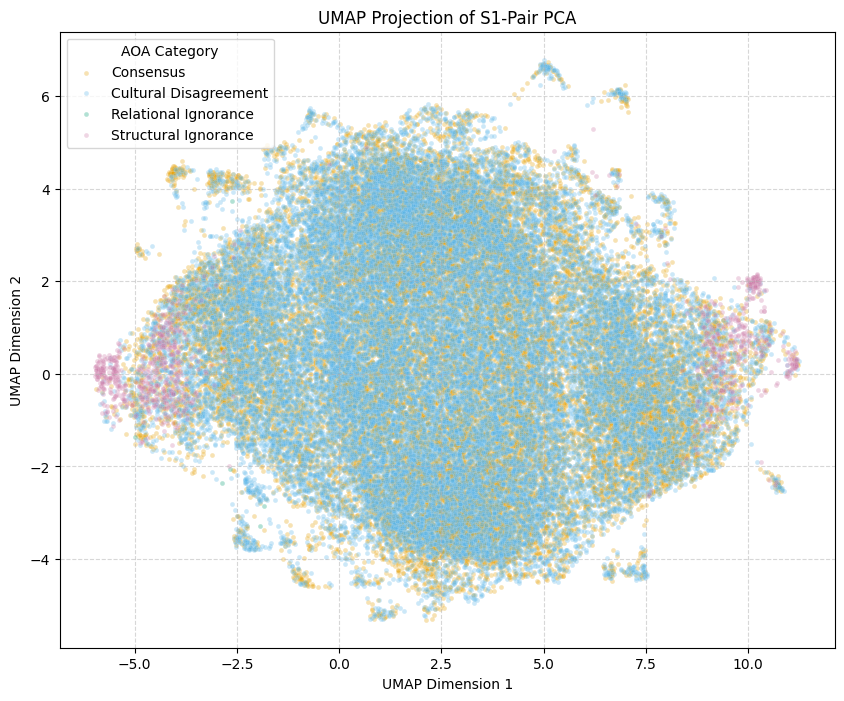

In [15]:
plt.figure(figsize=(10, 8))

# Plot each category iteratively to create a proper legend in matplotlib
for category in color_map.keys():
    mask = target_city_data['aoa_category'] == category
    if mask.any():
        plt.scatter(
            embedding_2d[mask, 0],
            embedding_2d[mask, 1],
            c=color_map[category],
            label=category,
            alpha=0.3,
            edgecolors='w',
            linewidth=0.2,
            s=12
        )

plt.title('UMAP Projection of S1-Pair PCA')
plt.xlabel('UMAP Dimension 1')
plt.ylabel('UMAP Dimension 2')
plt.legend(title="AOA Category")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

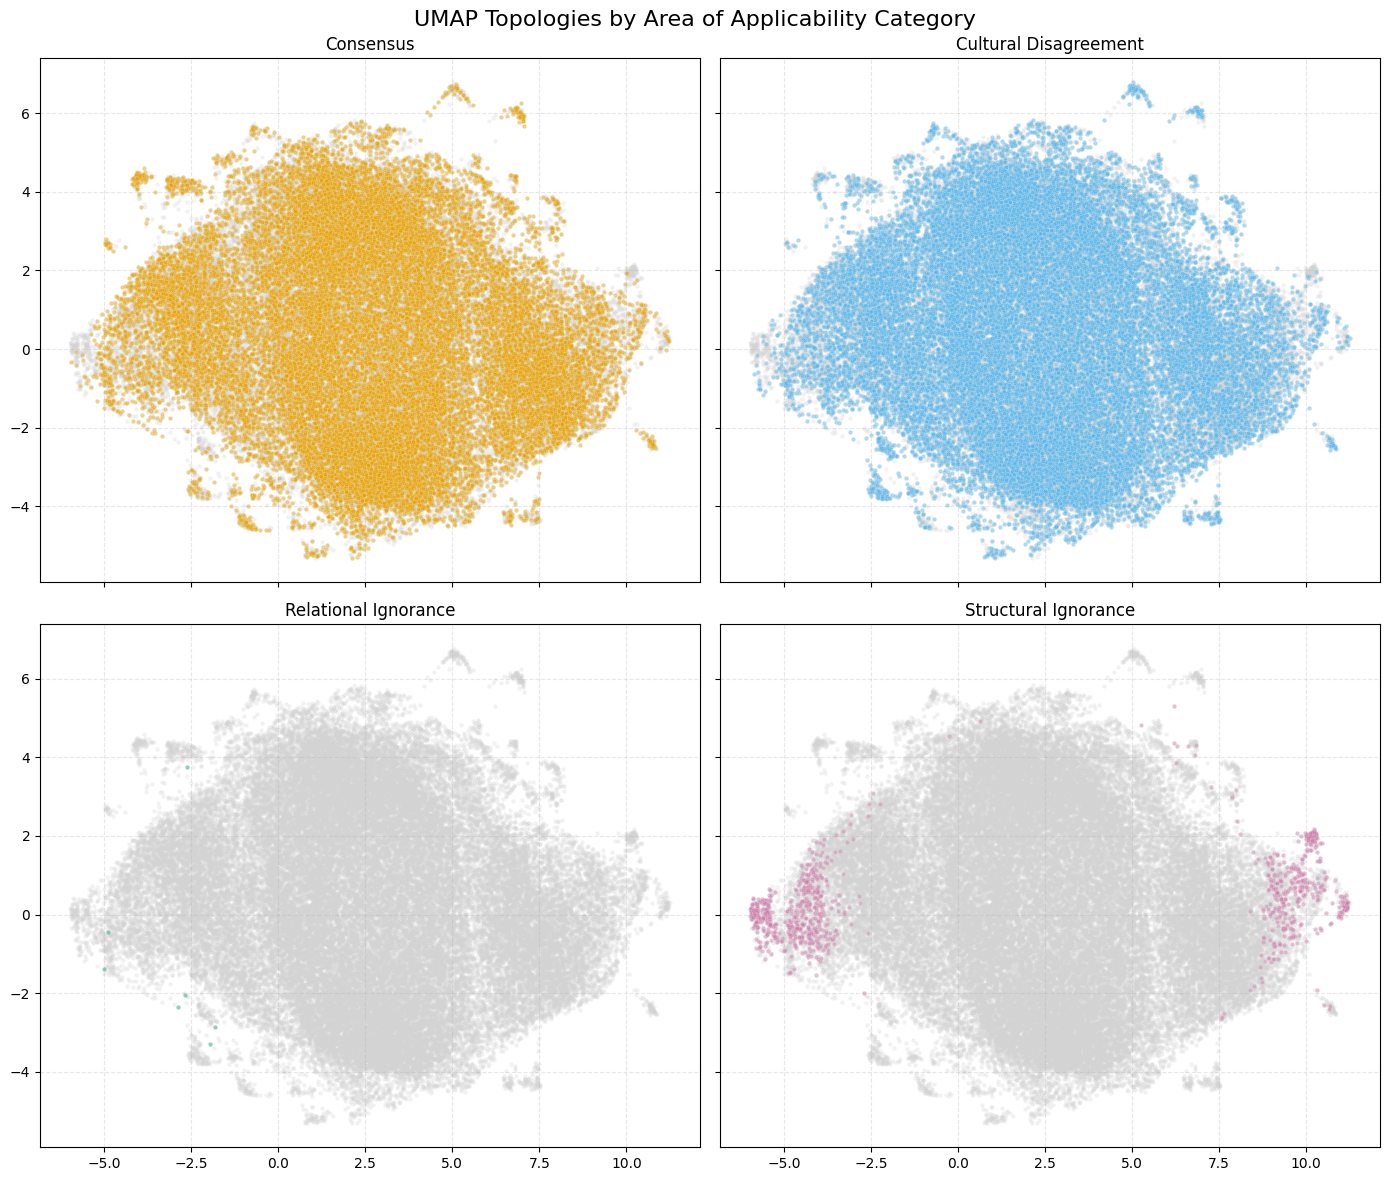

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(14, 12), sharex=True, sharey=True)
axes = axes.flatten()

categories = ['Consensus', 'Cultural Disagreement', 'Relational Ignorance', 'Structural Ignorance']

for idx, category in enumerate(categories):
    ax = axes[idx]
    mask = target_city_data['aoa_category'] == category
    
    # Plot all background points in light grey
    ax.scatter(embedding_2d[:, 0], embedding_2d[:, 1], c='lightgrey', alpha=0.2, s=5, zorder=1)
    
    # Plot the specific category points on top
    if mask.any():
        ax.scatter(
            embedding_2d[mask, 0],
            embedding_2d[mask, 1],
            c=color_map[category],
            alpha=0.4,
            edgecolors='w',
            linewidth=0.2,
            s=10,
            zorder=2
        )
    ax.set_title(category)
    ax.grid(True, linestyle='--', alpha=0.3)

plt.suptitle('UMAP Topologies by Area of Applicability Category', fontsize=16)
plt.tight_layout()
plt.show()